# 02 · Two-stage anchor-based: Faster R-CNN (torchvision `fasterrcnn_resnet50_fpn_v2`)
Protocol (identical for every detector in 02-05): train = every 6th frame of the 56 train clips, val = the 7 val
clips (split by clip), score = `src.eval.evaluate` on all 2846 val frames (COCO mAP@[.5:.95], maxDets 500,
ignore regions = crowd), speed = batch-1 end-to-end latency. Ignore regions are masked in the RPN / RoI losses.

Runs (each one changes one thing, ~T4 time): `frcnn_baseline` torchvision defaults 800/1333 (~1.7 h) →
`frcnn_giou` + GIoU box loss (~1.7 h) → `frcnn_sampler` + 2000 proposals / 50 % positive RoIs (~1.7 h) →
`frcnn_tuned` anchors 16-256 + 1024/1824 input + both changes (~3.5 h, writes a submission).
Everything is resumable: if the session dies, run the notebook again (finished runs are only reloaded).

In [1]:
# Paths: auto-detected for Colab, Kaggle and a local clone. Override by hand if your layout differs.
import os, sys
from pathlib import Path
if "google.colab" in sys.modules:
    ENV = "colab"
    from google.colab import drive
    drive.mount("/content/drive")                                   # outputs survive disconnects
    DATA_ROOT = Path("/content/data")                               # folder with test_images.csv
    REPO_DIR, WORK_DIR = Path("/content/Video-Detection-HW2"), Path("/content/drive/MyDrive/hw2_outputs")
elif os.environ.get("KAGGLE_KERNEL_RUN_TYPE"):                      # Colab also has /kaggle/input -> check env var
    ENV = "kaggle"
    DATA_ROOT = next(Path("/kaggle/input").glob("**/test_images.csv")).parent  # competition data
    REPO_DIR, WORK_DIR = Path("/kaggle/working/Video-Detection-HW2"), Path("/kaggle/working/outputs")
else:
    ENV = "local"
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA_ROOT, WORK_DIR = REPO_DIR / "data", REPO_DIR / "outputs"
assert (DATA_ROOT / "test_images.csv").exists(), f"test_images.csv not found in {DATA_ROOT}"
print("env:", ENV, "| DATA_ROOT:", DATA_ROOT, "| REPO_DIR:", REPO_DIR, "| WORK_DIR:", WORK_DIR)

env: local | DATA_ROOT: /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/data | REPO_DIR: /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2 | WORK_DIR: /Users/anastasiiayablunovska/year3/ai/Video-Detection-HW2/outputs


In [2]:
# Get the code + pinned dependencies on Kaggle / Colab (needs Internet). Locally nothing happens.
import subprocess
REPO_URL = "https://github.com/ystacy-ab/Video-Detection-HW2.git"
if ENV != "local":
    if (REPO_DIR / ".git").exists():
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "-q"], check=False)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO_DIR / "requirements.txt")], check=True)

In [3]:
# Make `src/` importable and print library versions (reproducibility)
sys.path.insert(0, str(Path(REPO_DIR).resolve()))
from src.utils import load_config, load_exp_config, seed_everything, print_versions, ensure_dir
print_versions()

python          3.12.6
numpy           2.4.6
torch           2.11.0
torchvision     0.26.0
ultralytics     8.4.208
faster_coco_eval 1.8.0
pycocotools     installed
ensemble_boxes  installed
sahi            0.14.0
cv2             5.0.0
wandb           0.31.0
device          CPU only


In [4]:
# Shared config + this notebook's experiment configs, seeds, output folders
cfg = load_config(Path(REPO_DIR) / "configs" / "base.yaml")
seed_everything(cfg["seed"])
DATA_ROOT, WORK_DIR = Path(DATA_ROOT), ensure_dir(WORK_DIR)
RES_DIR, FIG_DIR = Path(REPO_DIR) / "results", ensure_dir(Path(REPO_DIR) / "results" / "figures")
GT_VAL = DATA_ROOT / "val" / "annotations_coco.json"
EXPS = {n: load_exp_config(Path(REPO_DIR) / "configs" / f"{n}.yaml") for n in ['frcnn_baseline', 'frcnn_giou', 'frcnn_sampler', 'frcnn_tuned']}
RUN = list(EXPS)  # experiments this session may TRAIN; remove names to split the work over sessions
print("experiments:", RUN)

experiments: ['frcnn_baseline', 'frcnn_giou', 'frcnn_sampler', 'frcnn_tuned']


In [5]:
# Imports, GPU check and small helpers used below
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from src.utils import CLASS_NAMES, load_predictions
from src.eval import evaluate, per_class_table, evaluate_groups, clip_groups, density_groups
from src.viz import show_grid
from src import analysis as A
pd.set_option("display.width", 180)
RUN_GPU = torch.cuda.is_available()  # training / GPU-only cells are skipped on CPU
print("GPU:", torch.cuda.get_device_name(0) if RUN_GPU else "none -> training cells will be skipped")


def have(name, split="val"):
    return (WORK_DIR / "preds" / f"{name}_{split}.pkl").exists()


def compare(names, title=None):
    """COCO metrics of saved val predictions (same evaluator for every model)."""
    rows = {n: evaluate(load_predictions(WORK_DIR / "preds" / f"{n}_val.pkl"), GT_VAL, verbose=False)
            for n in names if have(n)}
    cols = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR"] + [f"AP_{c}" for c in CLASS_NAMES]
    t = pd.DataFrame(rows, index=cols).T.round(4)
    if title and len(t):
        t.to_csv(RES_DIR / f"{title}.csv")
    return t


def speed_table(names):
    """Speed / training time from results/experiments.csv (last row per experiment)."""
    e = pd.read_csv(RES_DIR / "experiments.csv")
    e = e[e["experiment"].isin(names)].drop_duplicates("experiment", keep="last")
    return e[["experiment", "val_mAP", "AP50", "AP_small", "ms_per_img", "FPS", "train_time_min"]]

from src.dataset import TVDetectionDataset, load_rgb, read_yolo_labels
from src.models_tv import rpn_recall, anchor_assignment_stats
from src.train_tv import run_experiment, prepare_indices, load_trained, get_device
from src.anchors import gt_wh_at_input, anchor_wh, anchor_coverage
DEVICE = get_device()
RESULTS = {}


def run_tv(name, test=False, notes=""):
    """Train + evaluate one config (resumable; a finished run is only reloaded, never re-logged)."""
    done = (WORK_DIR / "tv" / name / "final.json").exists()
    if not done and not (RUN_GPU and name in RUN):
        print(f"{name}: skipped (no GPU or not in RUN)")
        return None
    r = run_experiment(EXPS[name], DATA_ROOT, WORK_DIR, test=test and RUN_GPU, notes=notes)
    r.pop("model", None)
    if RUN_GPU:
        torch.cuda.empty_cache()
    RESULTS[name] = r
    display(r["per_class"].set_index("class").T.round(3))
    display(r["per_clip"].round(3))
    return r


def smoke(name):
    """Whole pipeline on 2 frames per clip / 40 iterations: catches path, memory and API errors first."""
    if not RUN_GPU:
        print("smoke test skipped (no GPU)")
        return
    torch.cuda.reset_peak_memory_stats()
    run_experiment(EXPS[name], DATA_ROOT, WORK_DIR, smoke=True)
    print(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
    torch.cuda.empty_cache()

GPU: none -> training cells will be skipped


## 1. Data pipeline check (CPU)

In [6]:
# Frame indices (same for every model): train every 6th frame, val subset for curves, all val frames for the score
train_idx, val_epoch_idx, val_full_idx = prepare_indices(EXPS["frcnn_baseline"], DATA_ROOT)

[index] train: 56 clips, 4062 frames (step=6)
[index] val: 7 clips, 2846 frames (step=1)
[data] train 4062 | val per-epoch 714 | val final 2846


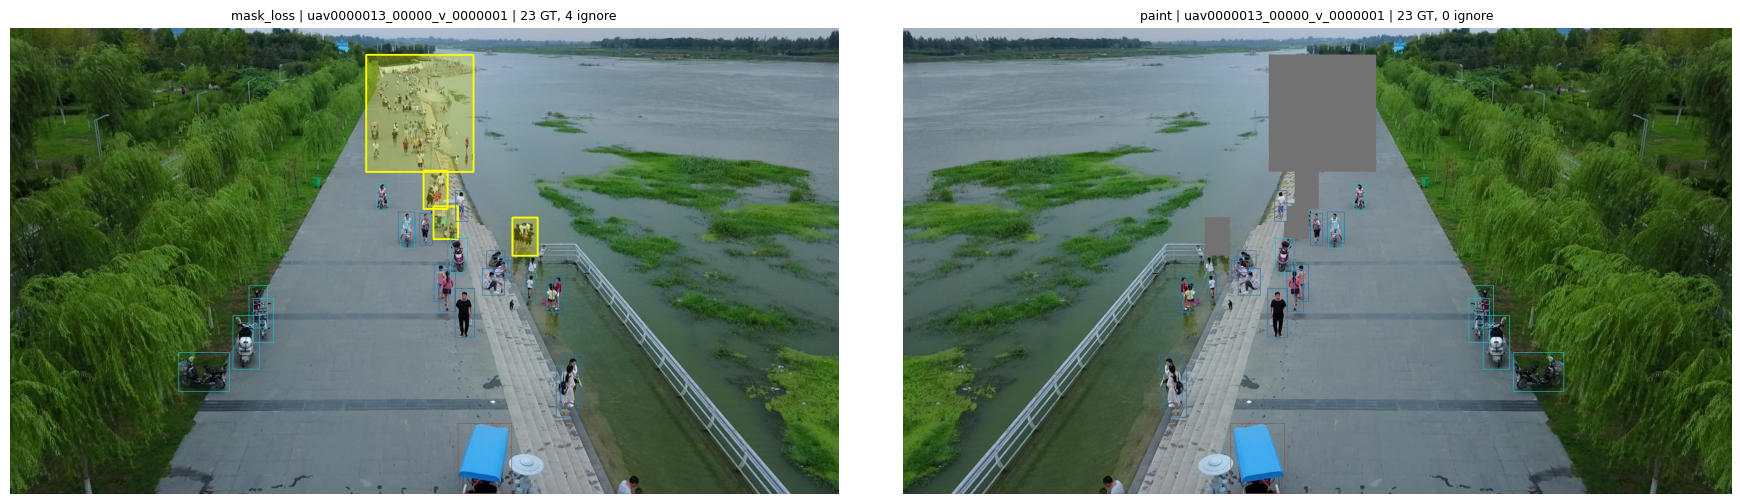

In [7]:
# One training sample per ignore mode. Left: mask_loss (flipped; ignore boxes yellow, used only in the loss).
# Right: paint fallback (gray regions, covered GT dropped). Boxes must sit exactly on the objects.
from src.viz import draw_boxes
i = int(np.argmax(train_idx["ignore_path"].astype(bool).values))  # first frame that has ignore regions
vis, titles = [], []
for mode, flip in [("mask_loss", 1.0), ("paint", 0.0)]:
    ds = TVDetectionDataset(train_idx, train=True, ignore_mode=mode, hflip=flip, max_short=1088, max_long=1824)
    img, tgt, meta = ds[i]
    b, ig = tgt["boxes"].numpy(), tgt["is_ignore"].numpy()
    vis.append(draw_boxes(img.permute(1, 2, 0).numpy()[:, :, ::-1].copy(), b[~ig], tgt["labels"].numpy()[~ig] - 1, ignore_xyxy=b[ig]))
    titles.append(f"{mode} | {meta['key']} | {(~ig).sum()} GT, {ig.sum()} ignore")
show_grid(vis, titles, ncols=2, figsize_per=(9, 5), save_path=FIG_DIR / "frcnn_dataset_check.png")

## 2. Anchors vs. object sizes at the network input (CPU)

In [8]:
# Share of GT boxes whose best anchor shape reaches IoU 0.5 / 0.7, with GT rescaled like the model transform does
rows = []
for n in ["frcnn_baseline", "frcnn_tuned"]:
    m = EXPS[n]["model"]
    wh = gt_wh_at_input(train_idx, m["min_size_test"], m["max_size"])
    rows.append({"config": n, "input": f"{m['min_size_test']}/{m['max_size']}", "anchors": m["anchor_sizes"],
                 **anchor_coverage(wh, anchor_wh(m["anchor_sizes"], m["aspect_ratios"]))})
pd.DataFrame(rows).to_csv(RES_DIR / "frcnn_anchor_coverage.csv", index=False)
pd.DataFrame(rows).round(3)

,config,input,anchors,median_obj_px,cover_IoU>=0.5,cover_IoU>=0.7
0,frcnn_baseline,800/1333,"[32, 64, 128, 256, 512]",31.768,0.746,0.370
1,frcnn_tuned,1024/1824,"[16, 32, 64, 128, 256]",43.385,0.994,0.507


## 3. Smoke test (GPU, ~5 min)
Heaviest config on 2 frames per clip. Minutes per real epoch ≈ (4062 / 2) / (it/s) / 60.

In [9]:
# Smoke test of the whole pipeline (train -> val -> speed) with frcnn_tuned
smoke("frcnn_tuned")

smoke test skipped (no GPU)


## 4. Baseline and ablations (800/1333)

In [10]:
# Baseline: torchvision defaults (anchors 32-512, 1000 test proposals, 25 % positive RoIs, smooth-L1)
run_tv("frcnn_baseline", notes="torchvision defaults, ignore=mask_loss");

frcnn_baseline: skipped (no GPU or not in RUN)


In [11]:
# Ablation 1 (loss modification): + GIoU box loss in the second stage
run_tv("frcnn_giou", notes="baseline + GIoU box loss (w=10)");

frcnn_giou: skipped (no GPU or not in RUN)


In [12]:
# Ablation 2 (proposals / RoI sampling): 2000 test proposals, 512 RPN anchors, 50 % positive RoIs
run_tv("frcnn_sampler", notes="baseline + 2000 proposals, rpn 512, roi pos 0.5");

frcnn_sampler: skipped (no GPU or not in RUN)


## 5. Final two-stage model (1024/1824, anchors 16-256) + test submission

In [13]:
# Tuned Faster R-CNN; also predicts the test set -> WORK_DIR/submissions/frcnn_tuned.csv (validated)
run_tv("frcnn_tuned", test=True, notes="anchors 16-256, 1024/1824 + jitter, GIoU, sampler");

frcnn_tuned: skipped (no GPU or not in RUN)


## 6. Comparison

In [14]:
# All Faster R-CNN runs on the same val protocol (metrics recomputed from the saved predictions) + speed
names = list(EXPS)
display(compare(names, "frcnn_comparison"))
speed_table(names)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor


,experiment,val_mAP,AP50,AP_small,ms_per_img,FPS,train_time_min


In [15]:
# Training curves: val-subset mAP and train loss per epoch (history.csv of each run)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n in EXPS:
    h = WORK_DIR / "tv" / n / "history.csv"
    if h.exists():
        h = pd.read_csv(h)
        ax[0].plot(h["epoch"], h["val_mAP"], marker="o", label=n); ax[1].plot(h["epoch"], h["loss"], marker="o", label=n)
ax[0].set(xlabel="epoch", ylabel="val mAP (every 4th frame)"); ax[1].set(xlabel="epoch", ylabel="train loss")
if ax[0].lines:
    ax[0].legend(); plt.tight_layout(); fig.savefig(FIG_DIR / "frcnn_curves.png", dpi=120); plt.show()
else:
    plt.close(fig); print("no history yet")

no history yet


## 7. Failure analysis (CPU, saved predictions of the best Faster R-CNN)
Operating point for pictures: score ≥ 0.3, IoU ≥ 0.5, class-agnostic matching (class confusion = "wrong class").

In [16]:
# Match the best run's predictions to the GT -> per-frame / per-GT / per-FP tables
t = compare(list(EXPS))
BEST = t["mAP"].idxmax() if len(t) else None
gt_val = A.gt_from_coco(GT_VAL)
key2path = dict(zip(val_full_idx["key"], val_full_idx["img_path"]))
HAVE_PREDS = BEST is not None
if HAVE_PREDS:
    preds = load_predictions(WORK_DIR / "preds" / f"{BEST}_val.pkl")
    frames, gts, fps = A.analyse_predictions(preds, gt_val, conf=0.3, iou_thr=0.5)
    print("analysing:", BEST)
    display(frames[["n_gt", "tp", "wrong_cls", "fn", "fp", "error_rate"]].describe().round(2))
else:
    print("no saved predictions -> section skipped")

no saved predictions -> section skipped


In [17]:
# Failure case 1: worst frames (highest error rate, >= 10 objects, one per clip). Green TP, orange wrong class, red missed, magenta FP
if HAVE_PREDS:
    worst = frames[frames["n_gt"] >= 10].sort_values("error_rate", ascending=False).drop_duplicates("clip").head(4)
    imgs = [A.draw_errors(load_rgb(key2path[k]), preds[k], gt_val[k]) for k in worst["key"]]
    show_grid(imgs, [f"{r.key}: {r.n_gt} GT | missed {r.fn} | wrong cls {r.wrong_cls} | FP {r.fp}" for r in worst.itertuples()],
              ncols=2, figsize_per=(9, 5), save_path=FIG_DIR / "frcnn_worst_frames.png")
    plt.figure(figsize=(6, 0.4)); plt.legend(handles=A.error_legend(), ncol=4, loc="center"); plt.axis("off"); plt.show()

In [18]:
# Failure case 2: class confusion (rows = GT, cols = prediction; last column = missed, last row = false positives)
if HAVE_PREDS:
    cm = A.confusion_matrix(gts, fps)
    fig, ax = plt.subplots(figsize=(8, 7))
    A.plot_confusion(cm, title=f"{BEST} (score>=0.3, IoU>=0.5)", ax=ax)
    fig.savefig(FIG_DIR / "frcnn_confusion.png", dpi=120, bbox_inches="tight"); plt.show()
    ci = {c: i for i, c in enumerate(CLASS_NAMES)}
    for a, b in [("van", "car"), ("car", "van"), ("truck", "van"), ("bicycle", "motor"), ("tricycle", "motor")]:
        print(f"GT {a:8s} -> predicted {b:6s}: {cm[ci[a], ci[b]] / max(cm[ci[a]].sum(), 1):.3f}")

In [19]:
# Failure case 3 and 4: recall per class by object size and by occlusion (0 none, 1 partial, 2 heavy)
if HAVE_PREDS:
    rec_size, rec_occ = A.recall_table(gts, "bucket"), A.recall_table(gts, "occ")
    rec_size.to_csv(RES_DIR / "frcnn_recall_by_size.csv"); rec_occ.to_csv(RES_DIR / "frcnn_recall_by_occlusion.csv")
    display(rec_size.round(3)); display(rec_occ.round(3))

In [20]:
# Crops: missed tiny people (< 16 px) and vans predicted as cars (context = 1x box size on each side)
if HAVE_PREDS:
    rng = np.random.default_rng(0)
    groups = {"missed person <16px": gts[(gts["cls"] == 0) & ~gts["matched"] & (gts["size"] < 16)],
              "van -> car": gts[(gts["cls"] == 3) & (gts["pred_cls"] == 2)]}
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
    for row, (name, g) in enumerate(groups.items()):
        pick = g.iloc[rng.choice(len(g), min(8, len(g)), replace=False)] if len(g) else g
        for ax in axes[row]: ax.axis("off")
        for ax, r in zip(axes[row], pick.itertuples()):
            ax.imshow(A.crop(load_rgb(key2path[r.key]), gt_val[r.key]["boxes"][r.gt_idx]))
            ax.set_title(f"{name}\n{r.size:.0f}px occ={r.occ}", fontsize=7)
    plt.tight_layout(); fig.savefig(FIG_DIR / "frcnn_failure_crops.png", dpi=120); plt.show()

In [21]:
# False positives by predicted class (high-score FPs = duplicates, unlabelled objects or class confusion)
if HAVE_PREDS:
    display(fps.assign(name=fps["pred_cls"].map(lambda c: CLASS_NAMES[c])).groupby("name").agg(
        n=("score", "size"), mean_score=("score", "mean"), high_score=("score", lambda s: int((s > 0.7).sum())),
        median_size=("size", "median")).reindex(CLASS_NAMES).round(3))

## 8. What each stage contributes: RPN proposal recall vs. final recall

In [22]:
# Recall of the top-N RPN proposals (class-agnostic, 150 val frames) vs. recall of the final detections.
# Objects missing from the proposals can never be detected; the gap to the final recall is lost in the box head.
rpn_rows = []
for n in ["frcnn_baseline", "frcnn_tuned"]:
    if (WORK_DIR / "tv" / n / "last.pt").exists():
        mdl = load_trained(EXPS[n], WORK_DIR, DEVICE)
        r = rpn_recall(mdl, val_full_idx, gt_val, EXPS[n]["model"]["min_size_test"], DEVICE,
                       n_images=150 if RUN_GPU else 10, max_long=EXPS[n]["model"]["max_size"])
        rpn_rows.append(r.assign(model=n)); del mdl
        if have(n):
            _, g, _ = A.analyse_predictions(load_predictions(WORK_DIR / "preds" / f"{n}_val.pkl"), gt_val, conf=0.05)
            g = g[g["key"].isin(set(val_full_idx["key"]))]
            fin = g.groupby("bucket")["matched"].mean().to_dict() | {"all": g["matched"].mean()}
            rpn_rows.append(pd.DataFrame([{"top_n": "final dets (score>=0.05)", "iou": 0.5, "bucket": b, "recall": v, "model": n}
                                          for b, v in fin.items()]))
if rpn_rows:
    rpn = pd.concat(rpn_rows)
    rpn.to_csv(RES_DIR / "frcnn_rpn_recall.csv", index=False)
    display(rpn[rpn["iou"] == 0.5].pivot_table(index=["model", "top_n"], columns="bucket", values="recall", sort=False).round(3))
else:
    print("no trained checkpoints yet")

no trained checkpoints yet
